In [1]:
# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.cluster import KMeans

# Data Preprocessing
from sklearn.preprocessing import StandardScaler

# Evaluation
from sklearn.metrics import silhouette_score

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("saquib7hussain/k-mean-cluster-dataset")

print("Path to dataset files:", path)

c:\Users\Ganesh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Ganesh\.cache\kagglehub\datasets\saquib7hussain\k-mean-cluster-dataset\versions\1


In [3]:
df = pd.read_csv(f"{path}/cluster_data.csv")

In [4]:
df.head()

,Feature 1,Feature 2
0,2.698582,-0.672960
1,-0.128113,4.355952
2,2.509049,5.773146
3,-1.518276,3.444886
4,-0.072283,2.883769


In [5]:
df.shape

(500, 2)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature 1  500 non-null    float64
 1   Feature 2  500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB


In [7]:
df.describe()

,Feature 1,Feature 2
count,500.000000,500.000000
mean,1.831353,2.694970
std,4.086149,3.494165
min,-3.896491,-4.378493
25%,-1.174033,0.200712
50%,0.604212,2.807746
75%,2.750212,5.132506
max,11.867680,10.216205


In [10]:
df.isnull().sum()

Feature 1    0
Feature 2    0
dtype: int64

In [11]:
print(df.info())
print(df.describe())

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature 1  500 non-null    float64
 1   Feature 2  500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB
None
        Feature 1   Feature 2
count  500.000000  500.000000
mean     1.831353    2.694970
std      4.086149    3.494165
min     -3.896491   -4.378493
25%     -1.174033    0.200712
50%      0.604212    2.807746
75%      2.750212    5.132506
max     11.867680   10.216205
Missing Values:
Feature 1    0
Feature 2    0
dtype: int64
Duplicate Rows: 0


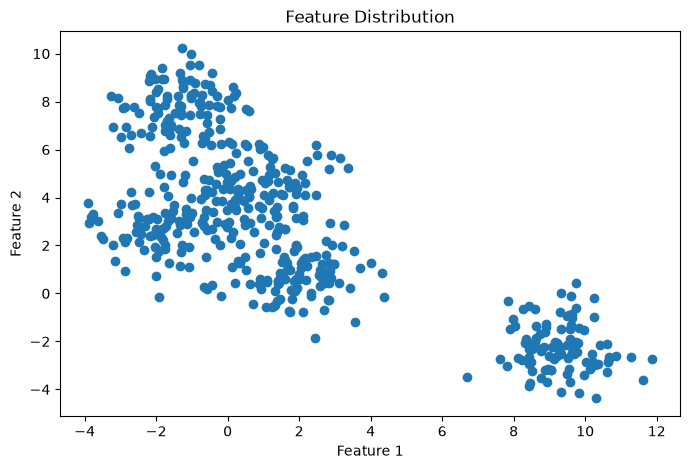

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Feature 1"], df["Feature 2"])

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Feature Distribution")

plt.show()

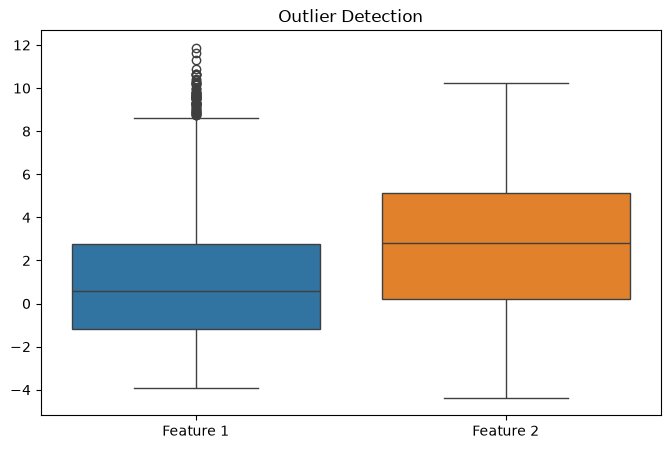

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df)

plt.title("Outlier Detection")

plt.show()

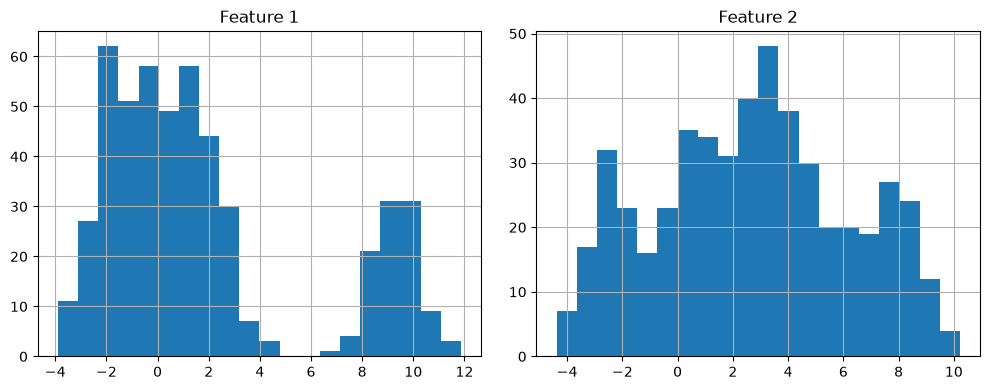

In [14]:
df.hist(figsize=(10, 4), bins=20)
plt.tight_layout()
plt.show()

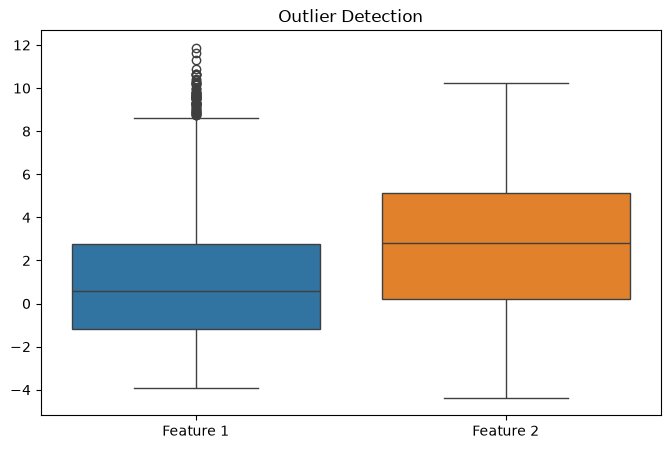

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df)
plt.title("Outlier Detection")
plt.show()

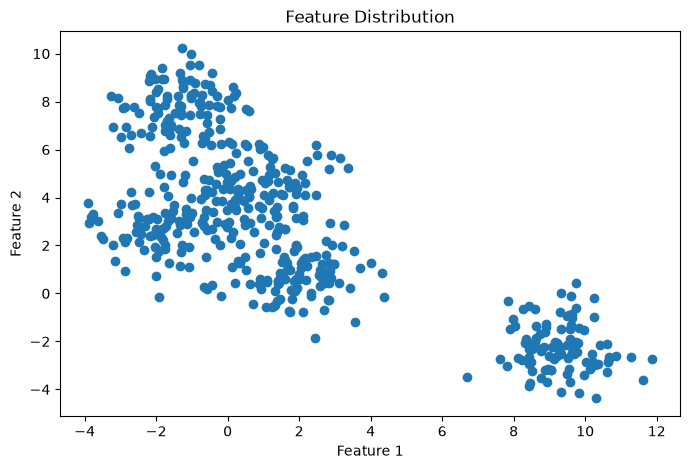

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Feature 1"], df["Feature 2"])

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Feature Distribution")

plt.show()

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=df.columns
)

scaled_df.head()

,Feature 1,Feature 2
0,0.212449,-0.964838
1,-0.480019,0.475835
2,0.166018,0.881830
3,-0.820573,0.214835
4,-0.466342,0.054087


In [18]:
scaled_df.describe()

,Feature 1,Feature 2
count,5.000000e+02,5.000000e+02
mean,4.352074e-17,-7.904788e-17
std,1.001002e+00,1.001002e+00
min,-1.403175e+00,-2.026392e+00
25%,-7.362423e-01,-7.145501e-01
50%,-3.006180e-01,3.230784e-02
75%,2.250968e-01,6.983004e-01
max,2.458642e+00,2.154668e+00


In [19]:
from sklearn.cluster import KMeans

wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(scaled_df)
    wcss.append(kmeans.inertia_)

print(wcss)

[1000.0, 329.49386929912765, 152.64280030364068, 93.13569952117648, 62.36217234183933, 55.468219042693285, 49.9762702669053, 44.70780795671117, 40.52195661131088, 36.48146116891894]


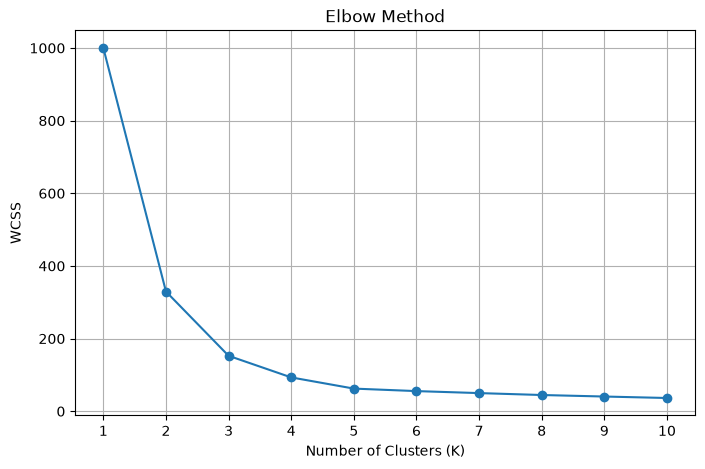

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [22]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for i in range(2, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(scaled_df)

    score = silhouette_score(scaled_df, labels)

    silhouette_scores.append(score)

print(silhouette_scores)

[0.6472054009723313, 0.5344656860278489, 0.53090913080148, 0.5581949755398367, 0.5001495133526679, 0.4712095547047322, 0.39222207769137346, 0.3512850142460744, 0.37497169963420174]


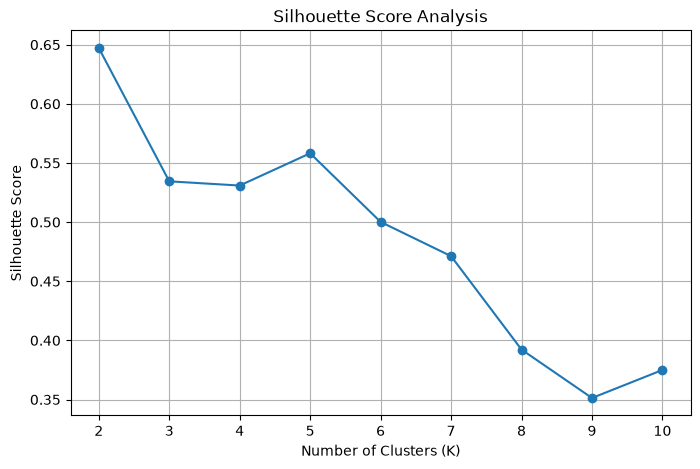

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_scores, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Analysis")

plt.xticks(range(2, 11))
plt.grid()
plt.show()

In [24]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(scaled_df)

df.head()

,Feature 1,Feature 2,Cluster
0,2.698582,-0.672960,1
1,-0.128113,4.355952,1
2,2.509049,5.773146,0
3,-1.518276,3.444886,1
4,-0.072283,2.883769,1


In [25]:
df["Cluster"].value_counts()

Cluster
1    259
0    141
2    100
Name: count, dtype: int64

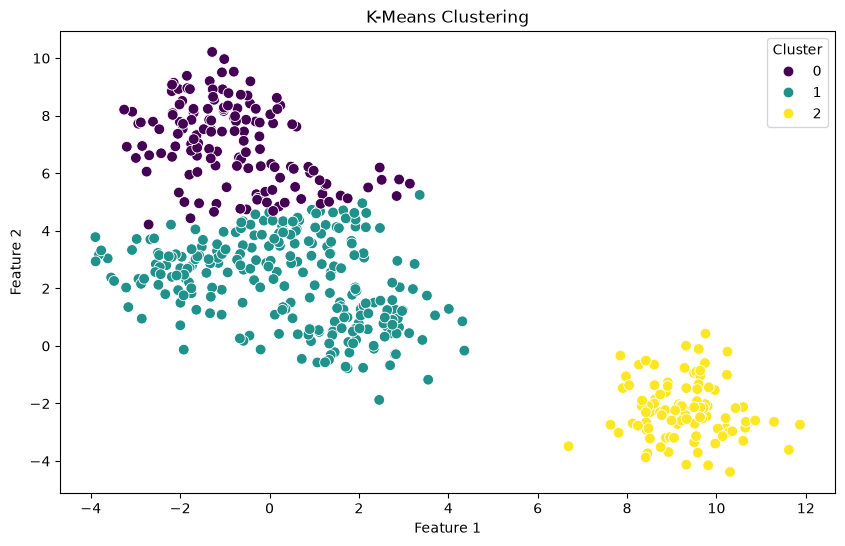

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Feature 1",
    y="Feature 2",
    hue="Cluster",
    palette="viridis",
    s=60
)

plt.title("K-Means Clustering")
plt.show()

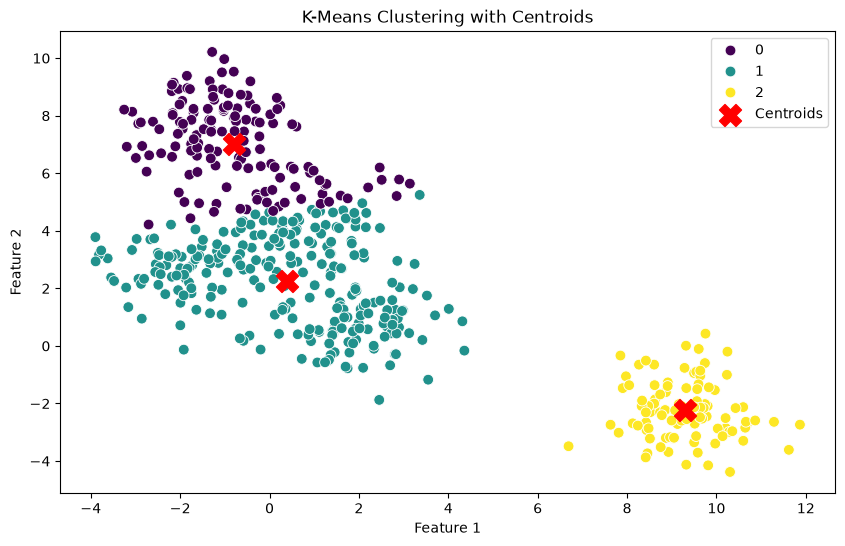

In [27]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Feature 1",
    y="Feature 2",
    hue="Cluster",
    palette="viridis",
    s=60
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    color="red",
    label="Centroids"
)

plt.title("K-Means Clustering with Centroids")
plt.legend()
plt.show()

In [28]:
df.groupby("Cluster").size()

Cluster
0    141
1    259
2    100
dtype: int64

In [29]:
cluster_analysis = df.groupby("Cluster").mean()

cluster_analysis

,Feature 1,Feature 2
Cluster,,
0,-0.802525,7.024069
1,0.380484,2.242834
2,9.302869,-2.238027


In [30]:
final_score = silhouette_score(
    scaled_df,
    df["Cluster"]
)

print("Final Silhouette Score:", final_score)

Final Silhouette Score: 0.5344656860278489


In [31]:
print("Model Inertia:", kmeans.inertia_)

Model Inertia: 152.64280030364068


In [32]:
import pickle

with open("kmeans_model.pkl", "wb") as file:
    pickle.dump(kmeans, file)

with open("scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

print("Model and Scaler Saved Successfully!")

Model and Scaler Saved Successfully!


In [34]:
with open("kmeans_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

with open("scaler.pkl", "rb") as file:
    loaded_scaler = pickle.load(file)

print("Model Loaded Successfully!")

Model Loaded Successfully!


In [35]:
import joblib

joblib.dump(kmeans, "kmeans_model.pkl")

['kmeans_model.pkl']